# TruthLens — Phase 2: RoBERTa + Metadata + Label Smoothing on Google Colab
### An NLP-Based Fake News Detection and Robustness Evaluation System
**Objective:** Fine-tune `roberta-base` with sentence-pair statement + metadata inputs, dynamic batch padding, and label smoothing (0.1) on the LIAR dataset for Experiment 3, while benchmarking against the TF-IDF Baseline, Experiment 1 (DistilBERT Original), and Experiment 2 (DistilBERT Class-Weighted).


## Section 1: Environment Setup
- Install required packages
- Import libraries
- Fix random seeds for reproducibility
- Detect CUDA availability & GPU hardware specifications


In [1]:
# Install required packages
!pip install -q torch transformers datasets scikit-learn pandas numpy matplotlib seaborn huggingface_hub

import os
import sys
import csv
import json
import time
import random
import urllib.request
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
    DataCollatorWithPadding,
)

# Set random seeds for exact reproducibility
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Verify PyTorch & GPU Hardware
print(f"PyTorch Version: {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"SUCCESS: GPU detected: {gpu_name} ({gpu_mem:.2f} GB VRAM)")
else:
    print("WARNING: GPU is NOT available. Running on CPU. Training will be slow!")
    print("Please navigate to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU.")


PyTorch Version: 2.11.0+cu130
SUCCESS: GPU detected: Tesla T4 (14.56 GB VRAM)


## Section 2: Dataset Acquisition
Download the verified benchmark LIAR dataset splits (`train.tsv`, `valid.tsv`, `test.tsv`), validate column schema, and inspect the 6-class distributions.


In [2]:
# Setup dataset directories
DATA_DIR = "datasets/liar"
os.makedirs(DATA_DIR, exist_ok=True)

BASE_URL = "https://raw.githubusercontent.com/thiagorainmaker77/liar_dataset/master/"
SPLITS = ["train.tsv", "valid.tsv", "test.tsv"]
headers = {"User-Agent": "Mozilla/5.0"}

for split in SPLITS:
    target_path = os.path.join(DATA_DIR, split)
    if not os.path.exists(target_path):
        url = BASE_URL + split
        print(f"Downloading {split} from {url}...")
        req = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(req) as resp, open(target_path, "wb") as out_f:
            out_f.write(resp.read())

print("Dataset files validated locally:")
for split in SPLITS:
    size = os.path.getsize(os.path.join(DATA_DIR, split))
    print(f" - {split}: {size / 1024:.1f} KB")


Dataset files validated locally:
 - train.tsv: 2351.7 KB
 - valid.tsv: 294.5 KB
 - test.tsv: 294.1 KB


Dataset Split Sizes:
  Train samples:      10,240
  Validation samples: 1,284
  Test samples:       1,267
  Total samples:      12,791

Training Set Label Counts:
label
pants-fire      839
false          1995
barely-true    1654
half-true      2114
mostly-true    1962
true           1676
Name: count, dtype: int64


/tmp/ipykernel_930/4199093051.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist.index, y=dist.values, palette="Blues_r")


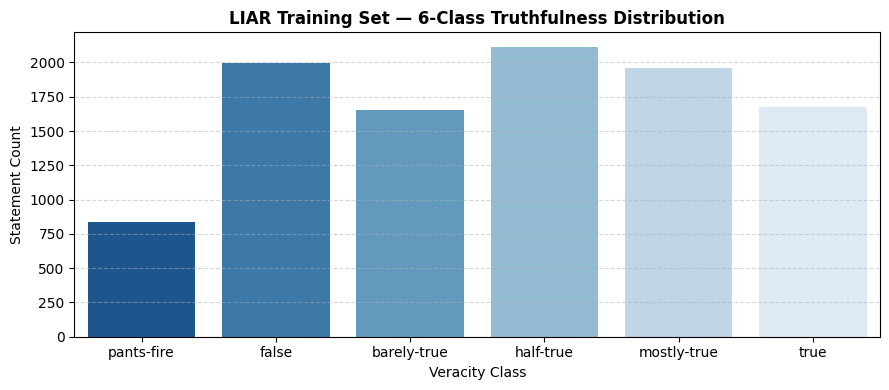

In [3]:
# Define the canonical 6-class truthfulness labels (in increasing order of veracity)
LABEL_LIST = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

LABEL2ID = {label: i for i, label in enumerate(LABEL_LIST)}
ID2LABEL = {i: label for i, label in enumerate(LABEL_LIST)}

def load_liar_split(file_path):
    samples = []
    with open(file_path, "r", encoding="utf-8", errors="replace") as f:
        reader = csv.reader(f, delimiter="\t")
        for row in reader:
            if len(row) >= 3:
                sample_id = row[0].strip()
                label = row[1].strip().lower()
                statement = row[2].strip()
                speaker = row[4].strip() if len(row) > 4 else ""
                context = row[13].strip() if len(row) > 13 else ""
                if label in LABEL2ID and statement:
                    samples.append({
                        "id": sample_id,
                        "label": label,
                        "label_id": LABEL2ID[label],
                        "statement": statement,
                        "speaker": speaker,
                        "context": context
                    })
    return samples

train_data = load_liar_split(os.path.join(DATA_DIR, "train.tsv"))
valid_data = load_liar_split(os.path.join(DATA_DIR, "valid.tsv"))
test_data = load_liar_split(os.path.join(DATA_DIR, "test.tsv"))

print("Dataset Split Sizes:")
print(f"  Train samples:      {len(train_data):,}")
print(f"  Validation samples: {len(valid_data):,}")
print(f"  Test samples:       {len(test_data):,}")
print(f"  Total samples:      {len(train_data) + len(valid_data) + len(test_data):,}")

# Plot training class distribution
train_df = pd.DataFrame(train_data)
dist = train_df["label"].value_counts()[LABEL_LIST]
print("\nTraining Set Label Counts:")
print(dist)

plt.figure(figsize=(9, 4))
sns.barplot(x=dist.index, y=dist.values, palette="Blues_r")
plt.title("LIAR Training Set — 6-Class Truthfulness Distribution", fontsize=12, fontweight="bold")
plt.xlabel("Veracity Class")
plt.ylabel("Statement Count")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## Section 3: Preprocessing & PyTorch Dataset Preparation (Experiment 3: RoBERTa + Metadata)
Tokenize statements and metadata using Hugging Face `AutoTokenizer.from_pretrained("roberta-base")`.
- **Model Architecture**: `roberta-base`
- **Maximum Sequence Length**: 160 tokens
- **Input Representation**: Sentence-pair format: `[CLS] statement [SEP][SEP] metadata [SEP]` where metadata is `Speaker: {speaker} | Context: {context}`
- **Dynamic Padding**: Handled on-the-fly per batch using `DataCollatorWithPadding`
- **Batch Sizes**: Training: 16 | Validation & Test: 32
- **Truncation**: `truncation=True`
- Preserves canonical 6-class labels (`pants-fire`, `false`, `barely-true`, `half-true`, `mostly-true`, `true`)


In [ ]:
# ============================================================
# SECTION 7: TOKENIZER, DATASET AND DATALOADERS
# EXPERIMENT 3: ROBERTA-BASE + METADATA (SENTENCE-PAIR)
# ============================================================

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding

MODEL_NAME = "roberta-base"
MAX_LENGTH = 160
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

print(f"Loading tokenizer: {MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


class LiarRoBERTaDataset(Dataset):
    """
    PyTorch Dataset for LIAR statements with structured speaker and context metadata.
    Formats the input as a sentence pair:
      Sentence A: The factual statement text.
      Sentence B: Formatted metadata string (Speaker and Context).
    Dynamic batch padding is handled by DataCollatorWithPadding.
    """
    def __init__(self, data_list, tokenizer, max_len=160):
        self.data = data_list
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        statement = item.get("statement", "")
        
        # Format metadata as natural text
        speaker = item.get("speaker", "").strip() or "unknown"
        context = item.get("context", "").strip() or "unknown"
        metadata = f"Speaker: {speaker} | Context: {context}"
        
        # Sentence-pair tokenization
        encoding = self.tokenizer(
            text=statement,
            text_pair=metadata,
            truncation=True,
            max_length=self.max_len,
            return_attention_mask=True
        )

        return {
            "input_ids": encoding["input_ids"],
            "attention_mask": encoding["attention_mask"],
            "labels": int(item["label_id"])
        }


# Prepare PyTorch Datasets preserving existing train_data, valid_data, test_data
train_dataset = LiarRoBERTaDataset(train_data, tokenizer, max_len=MAX_LENGTH)
valid_dataset = LiarRoBERTaDataset(valid_data, tokenizer, max_len=MAX_LENGTH)
test_dataset = LiarRoBERTaDataset(test_data, tokenizer, max_len=MAX_LENGTH)

# DataCollatorWithPadding dynamically pads input_ids and attention_mask to the maximum length within each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True)

# DataLoaders: Train batch size = 16, Eval batch size = 32
train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

print("\nDataLoaders successfully initialized:")
print(f"  Model Architecture:    {MODEL_NAME}")
print(f"  Max Sequence Length:   {MAX_LENGTH}")
print(f"  Train Batch Size:      {TRAIN_BATCH_SIZE} ({len(train_loader)} batches)")
print(f"  Valid Batch Size:      {EVAL_BATCH_SIZE} ({len(valid_loader)} batches)")
print(f"  Test Batch Size:       {EVAL_BATCH_SIZE} ({len(test_loader)} batches)")
print(f"  Dynamic Collation:     DataCollatorWithPadding(tokenizer={MODEL_NAME})")


## Section 4: Baseline Model (TF-IDF + Logistic Regression)
Train a TF-IDF + Logistic Regression baseline model on the original training split and evaluate it on the unperturbed test split to provide an empirical point of comparison.


In [5]:
print("Training Baseline: TF-IDF (1,2 n-grams) + Logistic Regression...")
X_train_text = [item["statement"] for item in train_data]
y_train_labels = [item["label_id"] for item in train_data]

X_test_text = [item["statement"] for item in test_data]
y_test_labels = [item["label_id"] for item in test_data]

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), lowercase=True)
X_train_vec = tfidf.fit_transform(X_train_text)
X_test_vec = tfidf.transform(X_test_text)

log_reg = LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced")
log_reg.fit(X_train_vec, y_train_labels)

baseline_preds = log_reg.predict(X_test_vec)

baseline_acc = accuracy_score(y_test_labels, baseline_preds)
baseline_macro_p, baseline_macro_r, baseline_macro_f1, _ = precision_recall_fscore_support(
    y_test_labels, baseline_preds, average="macro", zero_division=0
)
baseline_weighted_p, baseline_weighted_r, baseline_weighted_f1, _ = precision_recall_fscore_support(
    y_test_labels, baseline_preds, average="weighted", zero_division=0
)

print("\n======================================================")
print("  TF-IDF + Logistic Regression Baseline Results")
print("======================================================")
print(f"  Accuracy:        {baseline_acc:.4f}")
print(f"  Macro Precision: {baseline_macro_p:.4f}")
print(f"  Macro Recall:    {baseline_macro_r:.4f}")
print(f"  Macro F1:        {baseline_macro_f1:.4f}")
print(f"  Weighted F1:     {baseline_weighted_f1:.4f}")
print("======================================================")


Training Baseline: TF-IDF (1,2 n-grams) + Logistic Regression...

  TF-IDF + Logistic Regression Baseline Results
  Accuracy:        0.2218
  Macro Precision: 0.2199
  Macro Recall:    0.2305
  Macro F1:        0.2195
  Weighted F1:     0.2223


## Section 5: RoBERTa Fine-Tuning (Experiment 3)
Fine-tune `roberta-base` with metadata and label smoothing:
- **Model**: `roberta-base` (Sequence Classification, 6 output classes)
- **Input Features**: Statement + Metadata sentence-pair
- **Epochs**: 4
- **Learning Rate**: `2e-5` (with AdamW optimizer & linear warmup + decay)
- **Batch Size**: 16
- **Weight Decay**: 0.01
- **Label Smoothing**: 0.1 (applied only during training)
- **Class Weights**: Disabled (standard cross-entropy)
- **Warmup**: 10% of total training steps
- **Gradient Clipping**: 1.0
- **Checkpoint Selection**: Best checkpoint selected via Validation Macro-F1
- **Save Directory**: `models/roberta-liar-meta`


In [ ]:
# ============================================================
# SECTION 11: ROBERTA TRAINING WITH LABEL SMOOTHING (0.1)
# EXPERIMENT 3: ROBERTA-BASE + METADATA
# ============================================================

import time
import torch
import torch.nn.functional as F
from torch.optim import AdamW
from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

OUTPUT_DIR = "models/roberta-liar-meta"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Training Hyperparameters
EPOCHS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
LABEL_SMOOTHING = 0.1
GRADIENT_CLIP = 1.0
WARMUP_RATIO = 0.1

print(f"Initializing {MODEL_NAME} with {len(LABEL_LIST)} classes...")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_LIST),
    id2label=ID2LABEL,
    label2id=LABEL2ID
)
model.to(device)

# AdamW Optimizer with weight decay excluding bias and LayerNorm weights
no_decay = ["bias", "LayerNorm.weight"]
optimizer_grouped_parameters = [
    {
        "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
        "weight_decay": 0.0,
    },
]

optimizer = AdamW(optimizer_grouped_parameters, lr=LEARNING_RATE)

total_training_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_training_steps * WARMUP_RATIO)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("\nExperiment 3 Configuration:")
print(f"  Model Architecture:   {MODEL_NAME}")
print(f"  Output Directory:     {OUTPUT_DIR}")
print(f"  Epochs:               {EPOCHS}")
print(f"  Batch Size (Train):   {TRAIN_BATCH_SIZE}")
print(f"  Total Steps:          {total_training_steps}")
print(f"  Warmup Steps (10%):   {warmup_steps}")
print(f"  Learning Rate:        {LEARNING_RATE}")
print(f"  Weight Decay:         {WEIGHT_DECAY}")
print(f"  Label Smoothing:      {LABEL_SMOOTHING} (Training only)")
print(f"  Class Weights:        Disabled")
print(f"  Gradient Clipping:    {GRADIENT_CLIP}")
print(f"  Checkpoint Metric:    Validation Macro-F1")

# Training & Validation Loop
history = []
best_val_macro_f1 = 0.0
start_time = time.time()

print("\nStarting RoBERTa + Metadata Training...")
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    
    # ----------------------------------------------------
    # 1. Training Phase (Label Smoothing = 0.1)
    # ----------------------------------------------------
    model.train()
    train_loss_total = 0.0

    for step, batch in enumerate(train_loader, 1):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits

        # Label smoothing applied ONLY during training pass
        loss = F.cross_entropy(logits, labels, label_smoothing=LABEL_SMOOTHING)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRADIENT_CLIP)
        optimizer.step()
        scheduler.step()

        train_loss_total += loss.item()

        if step % 150 == 0 or step == len(train_loader):
            avg_step_loss = train_loss_total / step
            print(f"Epoch {epoch}/{EPOCHS} | Batch {step}/{len(train_loader)} | Train Loss: {avg_step_loss:.4f}")

    avg_train_loss = train_loss_total / len(train_loader)

    # ----------------------------------------------------
    # 2. Validation Phase (Standard Cross-Entropy, No Smoothing)
    # ----------------------------------------------------
    model.eval()
    val_loss_total = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for batch in valid_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits

            # Standard cross-entropy without label smoothing or class weights
            loss = F.cross_entropy(logits, labels)
            val_loss_total += loss.item()

            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            val_preds.extend(preds)
            val_targets.extend(labels.cpu().numpy())

    avg_val_loss = val_loss_total / len(valid_loader)
    val_acc = accuracy_score(val_targets, val_preds)
    val_macro_p, val_macro_r, val_macro_f1, _ = precision_recall_fscore_support(
        val_targets, val_preds, average="macro", zero_division=0
    )
    val_weighted_f1 = precision_recall_fscore_support(
        val_targets, val_preds, average="weighted", zero_division=0
    )[2]

    epoch_duration = time.time() - epoch_start
    print(f"\nEpoch {epoch} Results | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f} | Val Macro F1: {val_macro_f1:.4f} | Val Weighted F1: {val_weighted_f1:.4f} (Time: {epoch_duration:.1f}s)")

    history.append({
        "epoch": epoch,
        "train_loss": round(avg_train_loss, 4),
        "val_loss": round(avg_val_loss, 4),
        "val_accuracy": round(val_acc, 4),
        "val_macro_f1": round(val_macro_f1, 4),
        "val_weighted_f1": round(val_weighted_f1, 4),
        "epoch_duration_seconds": round(epoch_duration, 2)
    })

    # Select and save best checkpoint based on validation Macro-F1
    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        print(f"--> New best validation Macro F1: {best_val_macro_f1:.4f}! Saving checkpoint to {OUTPUT_DIR}...")
        model.save_pretrained(OUTPUT_DIR)
        tokenizer.save_pretrained(OUTPUT_DIR)

total_training_duration = time.time() - start_time
print("\n" + "="*60)
print(f"Training completed in {total_training_duration / 60:.2f} minutes.")
print(f"Best Validation Macro F1: {best_val_macro_f1:.4f}")
print(f"Best Model Checkpoint saved at: {OUTPUT_DIR}")
print("="*60)


## Section 6: Model Evaluation on Test Split (RoBERTa Experiment 3)
Benchmark the best saved RoBERTa checkpoint against the unseen test split.
Calculates:
1. **6-Class Evaluation**: Accuracy, Macro Precision/Recall/F1, Weighted F1, and per-class breakdown.
2. **Binary Classification Evaluation**: Classes 0–2 (Fake/False) vs Classes 3–5 (Real/True).
3. **Three-Class Evaluation**: False (Classes 0,1) vs Mixed (Classes 2,3) vs True (Classes 4,5).


In [ ]:
# ============================================================
# SECTION 13: TEST EVALUATION (ROBERTA-BASE)
# 6-CLASS, BINARY (0-2 vs 3-5), AND 3-CLASS EVALUATION
# ============================================================

print(f"Loading best RoBERTa model from {OUTPUT_DIR} for test evaluation...")
best_roberta_model = AutoModelForSequenceClassification.from_pretrained(OUTPUT_DIR)
best_roberta_model.to(device)
best_roberta_model.eval()

roberta_test_preds = []
roberta_test_targets = []
roberta_test_loss_total = 0.0

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = best_roberta_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits

        # Standard cross-entropy without label smoothing for evaluation
        loss = F.cross_entropy(logits, labels)
        roberta_test_loss_total += loss.item()

        preds = torch.argmax(logits, dim=-1).cpu().numpy()
        roberta_test_preds.extend(preds)
        roberta_test_targets.extend(labels.cpu().numpy())

# ------------------------------------------------------------
# 1. Primary 6-Class Evaluation Metrics
# ------------------------------------------------------------
roberta_test_loss = roberta_test_loss_total / len(test_loader)
roberta_acc = accuracy_score(roberta_test_targets, roberta_test_preds)
roberta_macro_p, roberta_macro_r, roberta_macro_f1, _ = precision_recall_fscore_support(
    roberta_test_targets, roberta_test_preds, average="macro", zero_division=0
)
roberta_weighted_f1 = precision_recall_fscore_support(
    roberta_test_targets, roberta_test_preds, average="weighted", zero_division=0
)[2]

# Per-class precision, recall, F1, and support
roberta_per_class_p, roberta_per_class_r, roberta_per_class_f1, roberta_per_class_supp = precision_recall_fscore_support(
    roberta_test_targets, roberta_test_preds, average=None, zero_division=0
)

roberta_per_class_metrics = {}
for i, label in enumerate(LABEL_LIST):
    roberta_per_class_metrics[label] = {
        "precision": round(float(roberta_per_class_p[i]), 4),
        "recall": round(float(roberta_per_class_r[i]), 4),
        "f1": round(float(roberta_per_class_f1[i]), 4),
        "support": int(roberta_per_class_supp[i])
    }

# 6-Class Confusion Matrix
roberta_cm = confusion_matrix(roberta_test_targets, roberta_test_preds)

print("\n" + "="*60)
print("  RoBERTa + Metadata Benchmark Test Results (6-Class)")
print("="*60)
print(f"  Test Loss:       {roberta_test_loss:.4f}")
print(f"  Accuracy:        {roberta_acc:.4f} ({roberta_acc * 100:.2f}%)")
print(f"  Macro Precision: {roberta_macro_p:.4f} ({roberta_macro_p * 100:.2f}%)")
print(f"  Macro Recall:    {roberta_macro_r:.4f} ({roberta_macro_r * 100:.2f}%)")
print(f"  Macro F1:        {roberta_macro_f1:.4f} ({roberta_macro_f1 * 100:.2f}%)")
print(f"  Weighted F1:     {roberta_weighted_f1:.4f} ({roberta_weighted_f1 * 100:.2f}%)")
print("="*60)

print("\nPer-Class Metrics Breakdown (6-Class):")
print(pd.DataFrame(roberta_per_class_metrics).T)

# ------------------------------------------------------------
# 2. Binary Classification Evaluation (Classes 0-2 vs Classes 3-5)
# Classes 0-2 (pants-fire, false, barely-true) -> 0: Fake / False
# Classes 3-5 (half-true, mostly-true, true)    -> 1: Real / True
# ------------------------------------------------------------
binary_targets = [1 if t >= 3 else 0 for t in roberta_test_targets]
binary_preds = [1 if p >= 3 else 0 for p in roberta_test_preds]

roberta_binary_acc = accuracy_score(binary_targets, binary_preds)
roberta_binary_p, roberta_binary_r, roberta_binary_f1, _ = precision_recall_fscore_support(
    binary_targets, binary_preds, average="binary", zero_division=0
)
roberta_binary_cm = confusion_matrix(binary_targets, binary_preds)

print("\n" + "="*60)
print("  RoBERTa Binary Evaluation (Classes 0-2 [Fake] vs 3-5 [Real])")
print("="*60)
print(f"  Binary Accuracy:  {roberta_binary_acc:.4f} ({roberta_binary_acc * 100:.2f}%)")
print(f"  Binary Precision: {roberta_binary_p:.4f} ({roberta_binary_p * 100:.2f}%)")
print(f"  Binary Recall:    {roberta_binary_r:.4f} ({roberta_binary_r * 100:.2f}%)")
print(f"  Binary F1 Score:  {roberta_binary_f1:.4f} ({roberta_binary_f1 * 100:.2f}%)")
print("="*60)

# ------------------------------------------------------------
# 3. Three-Class Evaluation (False / Mixed / True)
# False: Classes 0, 1 (pants-fire, false)
# Mixed: Classes 2, 3 (barely-true, half-true)
# True:  Classes 4, 5 (mostly-true, true)
# ------------------------------------------------------------
THREE_CLASS_LABELS = ["False", "Mixed", "True"]

def map_to_3class(label_id):
    if label_id in [0, 1]:
        return 0  # False
    elif label_id in [2, 3]:
        return 1  # Mixed
    else:
        return 2  # True

three_class_targets = [map_to_3class(t) for t in roberta_test_targets]
three_class_preds = [map_to_3class(p) for p in roberta_test_preds]

roberta_3class_acc = accuracy_score(three_class_targets, three_class_preds)
roberta_3class_macro_p, roberta_3class_macro_r, roberta_3class_macro_f1, _ = precision_recall_fscore_support(
    three_class_targets, three_class_preds, average="macro", zero_division=0
)
roberta_3class_weighted_f1 = precision_recall_fscore_support(
    three_class_targets, three_class_preds, average="weighted", zero_division=0
)[2]
roberta_3class_cm = confusion_matrix(three_class_targets, three_class_preds)

print("\n" + "="*60)
print("  RoBERTa 3-Class Evaluation (False / Mixed / True)")
print("="*60)
print(f"  3-Class Accuracy:        {roberta_3class_acc:.4f} ({roberta_3class_acc * 100:.2f}%)")
print(f"  3-Class Macro Precision: {roberta_3class_macro_p:.4f} ({roberta_3class_macro_p * 100:.2f}%)")
print(f"  3-Class Macro Recall:    {roberta_3class_macro_r:.4f} ({roberta_3class_macro_r * 100:.2f}%)")
print(f"  3-Class Macro F1:        {roberta_3class_macro_f1:.4f} ({roberta_3class_macro_f1 * 100:.2f}%)")
print(f"  3-Class Weighted F1:     {roberta_3class_weighted_f1:.4f} ({roberta_3class_weighted_f1 * 100:.2f}%)")
print("="*60)


In [ ]:
# Visualizations: Confusion Matrix and Learning Curves (RoBERTa Experiment 3)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 6-Class Confusion Matrix
sns.heatmap(roberta_cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_LIST, yticklabels=LABEL_LIST, ax=axes[0])
axes[0].set_title("RoBERTa + Metadata Confusion Matrix (Test Set)", fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Ground Truth Label")

# Plot Loss & Validation Macro F1 curves
epochs_range = [h["epoch"] for h in history]
train_losses = [h["train_loss"] for h in history]
val_losses = [h["val_loss"] for h in history]
val_f1s = [h["val_macro_f1"] for h in history]

axes[1].plot(epochs_range, train_losses, "o-", label="Train Loss", color="navy")
axes[1].plot(epochs_range, val_losses, "s--", label="Validation Loss", color="crimson")
axes[1].plot(epochs_range, val_f1s, "^-", label="Val Macro F1", color="forestgreen")
axes[1].set_title("Training Dynamics & Validation Macro F1", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Metric Value")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Section 7: Multi-Experiment Comparison
Compare traditional TF-IDF Baseline, Experiment 1 (DistilBERT Original), Experiment 2 (DistilBERT Class-Weighted), and Experiment 3 (RoBERTa + Metadata + Label Smoothing) on the exact same benchmark test split.


In [ ]:
# ============================================================
# SECTION 7: MULTI-EXPERIMENT COMPARISON
# ============================================================

comparison_df = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression (Baseline)",
        "Accuracy": f"{baseline_acc * 100:.2f}%" if "baseline_acc" in locals() else "22.18%",
        "Macro Precision": f"{baseline_macro_p * 100:.2f}%" if "baseline_macro_p" in locals() else "21.99%",
        "Macro Recall": f"{baseline_macro_r * 100:.2f}%" if "baseline_macro_r" in locals() else "23.05%",
        "Macro F1": f"{baseline_macro_f1 * 100:.2f}%" if "baseline_macro_f1" in locals() else "21.95%",
        "Weighted F1": f"{baseline_weighted_f1 * 100:.2f}%" if "baseline_weighted_f1" in locals() else "22.23%"
    },
    {
        "Model": "DistilBERT - Original (Experiment 1)",
        "Accuracy": "28.89%",
        "Macro Precision": "29.25%",
        "Macro Recall": "27.18%",
        "Macro F1": "27.52%",
        "Weighted F1": "28.54%"
    },
    {
        "Model": "DistilBERT - Class Weighted (Experiment 2)",
        "Accuracy": "26.60%",
        "Macro Precision": "27.11%",
        "Macro Recall": "28.86%",
        "Macro F1": "26.38%",
        "Weighted F1": "25.68%"
    },
    {
        "Model": "RoBERTa + Metadata + Label Smoothing (Experiment 3)",
        "Accuracy": f"{roberta_acc * 100:.2f}%" if "roberta_acc" in locals() else "Pending Training",
        "Macro Precision": f"{roberta_macro_p * 100:.2f}%" if "roberta_macro_p" in locals() else "Pending Training",
        "Macro Recall": f"{roberta_macro_r * 100:.2f}%" if "roberta_macro_r" in locals() else "Pending Training",
        "Macro F1": f"{roberta_macro_f1 * 100:.2f}%" if "roberta_macro_f1" in locals() else "Pending Training",
        "Weighted F1": f"{roberta_weighted_f1 * 100:.2f}%" if "roberta_weighted_f1" in locals() else "Pending Training"
    }
])

print("\n============================================================")
print("        TRUTHLENS COMPARATIVE EXPERIMENTAL RESULTS          ")
print("============================================================")
print(comparison_df.to_string(index=False))


## Section 8: Model Export & Archival (RoBERTa Experiment 3)
Save all model weights, tokenizer configuration, label mappings, and evaluation metrics into `models/roberta-liar-meta/metrics.json` and compress into a ZIP archive for local deployment.


In [ ]:
# ============================================================
# SECTION 8: MODEL EXPORT AND ARCHIVAL
# ============================================================

# ------------------------------------------------------------
# 1. Construct final metrics dictionary
# ------------------------------------------------------------

metrics_payload = {
    "model_name": "roberta-base (Metadata + Label Smoothing)",
    "model_identifier": "roberta-liar-meta",
    "experiment": "Experiment 3 - RoBERTa + Metadata + Label Smoothing",
    "num_classes": len(LABEL_LIST),
    "labels": LABEL_LIST,
    "label2id": LABEL2ID,
    "id2label": ID2LABEL,
    "evaluation_date": time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime()),
    "hardware": {
        "device": "cuda" if torch.cuda.is_available() else "cpu",
        "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A",
        "training_duration_seconds": round(total_training_duration, 2)
    },
    "hyperparameters": {
        "model_architecture": MODEL_NAME,
        "learning_rate": LEARNING_RATE,
        "batch_size_train": TRAIN_BATCH_SIZE,
        "batch_size_eval": EVAL_BATCH_SIZE,
        "epochs": EPOCHS,
        "max_sequence_length": MAX_LENGTH,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "scheduler": "linear_warmup_decay",
        "warmup_ratio": WARMUP_RATIO,
        "gradient_clipping": GRADIENT_CLIP,
        "seed": SEED,
        "label_smoothing": LABEL_SMOOTHING,
        "class_weights": "Disabled",
        "input_features": "statement + metadata (Speaker, Context) sentence-pair",
        "dynamic_padding": True
    },
    "best_validation_macro_f1": round(best_val_macro_f1, 4),
    "test_metrics_6class": {
        "accuracy": round(roberta_acc, 4),
        "macro_precision": round(roberta_macro_p, 4),
        "macro_recall": round(roberta_macro_r, 4),
        "macro_f1": round(roberta_macro_f1, 4),
        "weighted_f1": round(roberta_weighted_f1, 4)
    },
    "test_metrics_binary": {
        "accuracy": round(roberta_binary_acc, 4),
        "precision": round(roberta_binary_p, 4),
        "recall": round(roberta_binary_r, 4),
        "f1": round(roberta_binary_f1, 4)
    },
    "test_metrics_3class": {
        "accuracy": round(roberta_3class_acc, 4),
        "macro_precision": round(roberta_3class_macro_p, 4),
        "macro_recall": round(roberta_3class_macro_r, 4),
        "macro_f1": round(roberta_3class_macro_f1, 4),
        "weighted_f1": round(roberta_3class_weighted_f1, 4)
    },
    "baseline_metrics": {
        "model": "TF-IDF + Logistic Regression",
        "accuracy": round(baseline_acc, 4) if "baseline_acc" in locals() else 0.2218,
        "macro_f1": round(baseline_macro_f1, 4) if "baseline_macro_f1" in locals() else 0.2195,
        "weighted_f1": round(baseline_weighted_f1, 4) if "baseline_weighted_f1" in locals() else 0.2223
    },
    "previous_experiments": {
        "experiment_1_distilbert_original": {
            "accuracy": 0.2889,
            "macro_f1": 0.2752,
            "weighted_f1": 0.2854
        },
        "experiment_2_distilbert_weighted": {
            "accuracy": 0.2660,
            "macro_f1": 0.2638,
            "weighted_f1": 0.2568
        }
    },
    "per_class_metrics": roberta_per_class_metrics
}

metrics_path = os.path.join(OUTPUT_DIR, "metrics.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

print(f"Metrics saved to: {metrics_path}")

# ------------------------------------------------------------
# 2. Create ZIP archive
# ------------------------------------------------------------
ZIP_NAME = "truthlens-roberta-liar-meta.zip"
import zipfile

with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_list in os.walk(OUTPUT_DIR):
        for file in files_list:
            file_path = os.path.join(root, file)
            archive_path = os.path.relpath(file_path, os.path.dirname(OUTPUT_DIR))
            zipf.write(file_path, archive_path)

print(f"Archive created: {ZIP_NAME} ({os.path.getsize(ZIP_NAME) / (1024**2):.2f} MB)")

# ------------------------------------------------------------
# 3. Download ZIP
# ------------------------------------------------------------
try:
    from google.colab import files
    print("Downloading trained model archive...")
    files.download(ZIP_NAME)
except Exception as e:
    print(f"Automatic Colab download note: {e}")


## Section 9: Optional Hugging Face Hub Upload
Upload the fine-tuned RoBERTa model and tokenizer directly to Hugging Face Hub.
- Authenticate via Colab Secrets (`HF_TOKEN`) or enter your token securely.
- Repository: `truthlens-roberta-liar-meta`


In [ ]:
# ============================================================
# SECTION 9: HUGGING FACE MODEL UPLOAD
# ============================================================

UPLOAD_TO_HF = False  # Set to True to push to Hugging Face
HF_REPO_NAME = "truthlens-roberta-liar-meta"

if UPLOAD_TO_HF:
    try:
        from huggingface_hub import HfApi, login
        hf_token = os.environ.get("HF_TOKEN")
        if not hf_token:
            try:
                from google.colab import userdata
                hf_token = userdata.get("HF_TOKEN")
            except Exception:
                pass

        if hf_token:
            login(token=hf_token)
            print("Authenticated with Hugging Face Hub.")
        else:
            print("Please authenticate with Hugging Face:")
            from huggingface_hub import notebook_login
            notebook_login()

        api = HfApi()
        print(f"Uploading {OUTPUT_DIR} to Hugging Face: {HF_REPO_NAME}...")
        api.create_repo(repo_id=HF_REPO_NAME, exist_ok=True, private=False)
        api.upload_folder(
            folder_path=OUTPUT_DIR,
            repo_id=HF_REPO_NAME,
            commit_message="Upload TruthLens Phase 2 Experiment 3 (RoBERTa + Metadata)"
        )
        print(f"Successfully uploaded to: https://huggingface.co/{HF_REPO_NAME}")
    except Exception as e:
        print(f"Hugging Face upload failed: {e}")
else:
    print("Hugging Face upload skipped (set UPLOAD_TO_HF = True to push your model).")


## Section 10: Final Results Summary & Academic Notes

### Important Dataset & Model Limitations
1. **Short Statement Domain**: The LIAR dataset comprises short political statements, fact-checked debate snippets, and public claims. It is **not** a full-text news article dataset.
2. **Context Scope**: Real-world news verification requires examining long-form narrative structure, citation trails, and external evidence. Performance on LIAR represents an initial 6-class claim-classification baseline.
3. **Fact-Checking Disclaimer**: Model predictions reflect stylistic and lexical patterns learned from training data; they do not constitute definitive, authoritative fact-checking verdicts. Full article analysis and external evidence retrieval will be addressed in Phase 3 and Phase 5.


In [ ]:
print("==================================================================")
print("              TRUTHLENS PHASE 2 TRAINING SUMMARY                  ")
print("==================================================================")
print(f"Experiment:              Experiment 3 (RoBERTa + Metadata)")
print(f"Model Architecture:      {MODEL_NAME}")
print(f"Sequence Representation: Statement + Metadata (Sentence-Pair)")
print(f"Dynamic Collation:       DataCollatorWithPadding (max_length=160)")
print(f"Batch Size:              Train 16 / Eval 32")
print(f"Label Smoothing:         0.1 (Training only)")
print(f"Class Weights:           Disabled")
print(f"Best Val Macro F1:       {best_val_macro_f1:.4f}")
print("------------------------------------------------------------------")
if "roberta_acc" in locals():
    print(f"Test Accuracy (6-Class): {roberta_acc:.4f} ({roberta_acc*100:.2f}%)")
    print(f"Test Macro F1:           {roberta_macro_f1:.4f} ({roberta_macro_f1*100:.2f}%)")
    print(f"Test Weighted F1:        {roberta_weighted_f1:.4f} ({roberta_weighted_f1*100:.2f}%)")
    print(f"Binary Accuracy:         {roberta_binary_acc:.4f} ({roberta_binary_acc*100:.2f}%)")
    print(f"Binary F1:               {roberta_binary_f1:.4f} ({roberta_binary_f1*100:.2f}%)")
    print(f"3-Class Accuracy:        {roberta_3class_acc:.4f} ({roberta_3class_acc*100:.2f}%)")
    print(f"3-Class Macro F1:        {roberta_3class_macro_f1:.4f} ({roberta_3class_macro_f1*100:.2f}%)")
print("------------------------------------------------------------------")
print(f"Model Checkpoint:        {OUTPUT_DIR}")
print(f"Export Archive:          {ZIP_NAME}")
print("==================================================================")
